In [6]:
# -*- coding: utf-8 -*-
"""
Code for "Closed-form max-min power control for some cellular and cell-free massive MIMO networks"
Output: Comparison among different APs cooperation constraints (Fig. 2)
Author: Lorenzo Miretti

License: This code is licensed under the GPLv2 license. If you in any way
use this code for research that results in publications, please cite our
paper as described in the README file
"""
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from numpy import sqrt, log2, log10, diag, eye
from numpy.linalg import norm, inv, pinv
from scipy.linalg import sqrtm
from pprint import pprint


N_setups = 1          # Number of setups (random user positions) #2
N_sim = 100             # Monte Carlo samples for estimating statistical quantities
L = 2**2               # number of APs (must be a square number)
N = 2                  # number of AP antennas 
K = 3                  # number of UEs
Q = 2                   # cluster size (Q <= L)
squareLength  = 100    # lenght of squared service area [m]
p_max = 200             # UE power budget [mW]
# beamformer
#bf = 'LTMMSE'
bf = 'MF'


def get_vectors(interf, signal, noise, p_max):
    #A = np.ones((K, K))
    A = np.eye(K)    
    k = 0
    a_ks = [A[k, :].reshape((K,1)) for k in range(K)]
    
    b = signal
    sig = noise    
    C = interf
    M = inv(diag(b)) @ C.T
    u = inv(diag(b)) @ sig.reshape((K,1))    
    #M_k = M + (u @ a_k.T) / p_max
    M_ks = [M + (u @ a_ks[k].T) / p_max for k in range(K)]

    return {'M': M, 'u': u, 'b': b, 'A': A, 'Mks': M_ks}

def max_min_power_control(interf,signal,noise,p_max):
    #A = np.ones((K, K))
    A = np.eye(K)
    b = signal
    C = interf
    sig = noise
    M = inv(diag(b)) @ C.T
    u = inv(diag(b)) @ sig.reshape((K,1))
    rad_opt = 0
    for k in range(K): 
        a_k = A[k,:].reshape((K,1))
        M_k = M + (u @ a_k.T) / p_max
        rad = np.max(np.real(np.linalg.eigvals(M_k)))
        if rad > rad_opt:
            rad_opt = rad
        t_opt = 1/rad_opt
    p_opt = t_opt*inv(np.eye(K)-t_opt*M)@u
    return p_opt.reshape(K), log2(1+t_opt)

def compute_SINR(interf,signal,noise,p):
    SINR = [p[k]*signal[k]/((interf[:,k]) @ p + noise[k]) for k in range(K)]
    return SINR

def compute_channel_coefficients(H_list,H_hat_list,combiner,parameters):
    ''' Numerically evaluate the equivalent channel coefficients for the UatF bound.
    ''' 
    interf = np.zeros((K,K))
    signal = np.zeros(K,dtype=complex)
    noise = np.zeros(K)    
    for n in range(N_sim):
        # Compute combiners
        H_hat = H_hat_list[n] 
        V = combiner(H_hat,parameters)
        # Equivalent channel
        H = H_list[n] 
        H_eq = np.zeros((K,K),dtype=complex)
        # Updated statistics
        for l in range(L):
            H_eq += H[l] @ V[l] 
            noise += np.square(norm(V[l],axis=0))/N_sim     
        interf += np.square(np.abs(H_eq))/N_sim
        signal += diag(H_eq)/N_sim
    signal = np.square(np.abs(signal))  
    interf = interf-np.diag(signal)
    return  interf, signal, noise

def MMSE(H_hat,parameters):
    """ Centralized MMSE combining
    """
    UE_clusters = parameters[0]
    Psi_list = parameters[1]
    p = parameters[2]
    Q = len(UE_clusters[0])
    V_list = [np.zeros((N,K),dtype=complex) for _ in range(L)]
    for k in range(K):
        H_k = np.zeros((K,Q*N),dtype=complex)
        Psi_k = np.zeros((Q*N,Q*N),dtype=complex)
        for q in range(Q):
            l = UE_clusters[k][q]
            H_k[:,q*N:(q+1)*N] = H_hat[l]
            Psi_k[q*N:(q+1)*N,q*N:(q+1)*N] = Psi_list[l]
        V_MMSE = inv(herm(H_k)@ diag(p) @ H_k + Psi_k + eye(Q*N)) @ herm(H_k) @ diag(sqrt(p))
        for q in range(Q):
            l = UE_clusters[k][q]
            V_list[l][:,k] = V_MMSE[q*N:(q+1)*N,k]
    return V_list     

def MF(H_hat,parameters):
    """ MF combining
    """
    V_list = [] 
    for l in range(L):
        H =  H_hat[l]
        V_MF = herm(H) 
        V_list.append(V_MF) 
    return V_list

def LTMMSE(H_hat,parameters):
    """ Local TMMSE combining
    """
    W_list = parameters[0]
    Psi_list = parameters[1]
    p = parameters[2]
    V_list = [] 
    V = np.zeros((L*N,K),dtype = complex)
    for l in range(L):
        H = H_hat[l]
        V_LMMSE = pinv(herm(H)@ diag(p) @ H + Psi_list[l]*eye(N) + eye(N)) @ herm(H) @ diag(sqrt(p)) 
        V_list.append(V_LMMSE @ W_list[l]) 
    return V_list #V

def compute_parameters_LTMMSE(H_hat_list,Gamma,clusters,p):
    """ Computation of statistical parameters for LTMMSE combining. 
    """
    # Compute error covariances from path loss and power 
    # (scaled identities, so we keep only the scaling)
    AP_clusters = clusters[1]
    Psi_list = [] 
    for l in range(L):
        not_served_UE_list = list(range(K))
        for k in AP_clusters[l]:
            not_served_UE_list.remove(k)
        Psi_list.append(p[not_served_UE_list] @ Gamma[not_served_UE_list,l])

    # Estimate regularized and normalized covariance matrices
    UE_clusters = clusters[0]
    Pi_list = [] 
    for l in range(L):
        Pi_l = np.zeros((K,K),dtype=complex)
        for n in range(N_sim):
            H = diag(sqrt(p))@ H_hat_list[n][l] 
            Pi_l += H @ inv(herm(H) @ H + Psi_list[l]*eye(N) + eye(N)) @ herm(H) 
        Pi_list.append(Pi_l / N_sim)

    # Compute large scale fading decoding coefficients 
    # Initialize some useful variables
    Q = len(UE_clusters[0])
    W_list = [np.zeros((K,K),dtype=complex) for _ in range(L)]
    B = np.zeros((K*Q,K), dtype = complex)
    for l in range(Q):
        B[K*l:K*(l+1),:] = np.eye(K,dtype=complex)
    # Solve system for every UE k
    for k in range(K):
        A = np.zeros((K*Q,K*Q),dtype=complex)
        for l in range(Q):
            for j in range(Q):
                if j == l:
                    A[K*l:K*(l+1),K*l:K*(l+1)] = np.eye(K,dtype=complex)
                else:
                    A[K*l:K*(l+1),K*j:K*(j+1)] = Pi_list[UE_clusters[k][j]]
        w_k = inv(A) @ B[:,k]
        # Write coefficient onto W_list
        for l in range(Q):
            i = UE_clusters[k][l] 
            W_list[i][:,k] = w_k[K*l:K*(l+1)]
    return W_list, Psi_list

def generate_setup(plot = False):
    ''' Squared service area of length squareLength. Grid of APs, uniformely distributed APs. 
        set plot = True for visualizing the setup.'''
    sqrtL = int(sqrt(L)) 
    # Positions of APs (in meters, Cartesian coordinates)
    x = np.linspace(0,squareLength,sqrtL+1)   # "cell" boundaries on the x axis
    y = np.linspace(0,squareLength,sqrtL+1)   # "cell" boundaries on the y axis 
    x_AP = (x[:-1]+x[1:])/2
    y_AP = (y[:-1]+y[1:])/2
    pos_APs = []
    for i in range(sqrtL):
        for j in range(sqrtL):
            pos = np.array([x_AP[i],y_AP[j]])
            pos_APs.append(pos)
    # Position of UEs (in meters, Cartesian coordinates)
    pos_UEs = [squareLength*np.random.rand(2) for _ in range(K)]
    # Plot 
    if plot == True:
        plt.figure()
        fontSize = 15
        for k in range(K):
            if k == 0:
                plt.plot(pos_UEs[k][0],pos_UEs[k][1],'rv',label="UE")
            else:
                plt.plot(pos_UEs[k][0],pos_UEs[k][1],'rv')
        for l in range(L):
            if l == 0:
                plt.plot(pos_APs[l][0],pos_APs[l][1],'ob',label="AP")
            else:
                plt.plot(pos_APs[l][0],pos_APs[l][1],'ob')
        plt.xlabel('x [m]',fontsize = fontSize)
        plt.ylabel('y [m]',fontsize = fontSize)
        plt.axis('square')
        plt.xlim(0,squareLength)
        plt.ylim(0,squareLength)
        plt.xticks(x,fontsize = fontSize-2)
        plt.yticks(y,fontsize = fontSize-2)
        plt.legend()
        plt.grid()
        
        plt.show()
    pos = (pos_UEs,pos_APs,)
    return pos

def compute_ch_statistics(pos):
    """ Path loss model: 
        "Further advancements for E-UTRA physical layer aspects (Release 9)." 3GPP TS 36.814, Mar. 2017.
        3GPP UMi NLOS, exagonal layout, table B.1.2.1-1 and B.1.2.2.1-4.
        Same as Demir, Björnson and Sanguinetti, "Foundations of User-Centric Cell-Free Massive MIMO," 2021.
    """ 
    # Carrier frequency (GHz)
    f_c = 2  
    # Pathloss exponent
    PL_exp = 3.67  
    # Average channel gain in dB at a reference distance of 1 meter 
    Gamma_const = -22.7 
    # Minimum distance (i.e., the difference in height) between AP and UE in meters
    d_min = 10
    # Shadow fading std deviation [dB]
    sig_SF = 4
    # Bandwidth [Hz]
    B = 20*10**6
    # Noise figure [dB]
    noiseFigure = 7
    # Noise power [dBm]
    N0 = -174 + 10*log10(B) + noiseFigure
    # # Angular spread [rad]
    # ang_spread = 5/360*2*np.pi
    
    # UEs-APs distances (including d_min height difference), used for path loss computation
    pos_UEs = pos[0]
    pos_APs = pos[1]
    dist = np.zeros((K,L))
    for k in range(K):
        for l in range(L):
                dist[k,l]= np.sqrt(norm(pos_UEs[k]-pos_APs[l])**2 + d_min**2)

    # Uncorrelated shadow fading
    SF = sig_SF*np.random.randn(K,L)
    # UEs-UEs distances, used for computating shadow fading covariance matrices
    delta = np.zeros((K,K))
    for k in range(K):
        for j in range(K):
            delta[k,j] = norm(pos_UEs[k]-pos_UEs[j])
    # Correlated shadow fading (for each AP)
    for l in range(L):
        CovSF = np.power(2,-delta/9)  # SF covariance matrix (normalized by SF variance)
        SF[:,l] = sqrtm(CovSF) @ SF[:,l]

    # Channel gain (normalized by noise power)
    GammadB = Gamma_const - PL_exp*10*log10(dist) - 26*log10(f_c) - SF - N0
    Gamma = 10**(GammadB/10)
    return Gamma

def compute_clusters(Gamma,Q):
    """ User-centric cooperation clusters. Each user is served by the Q strongest APs.
    """
    Gamma_sorted_indexes = np.argsort(Gamma,axis=1)
    UE_clusters = Gamma_sorted_indexes[:,-Q:]
    AP_clusters = [[] for _ in range(L)]
    for k in range(K):
        for q in range(Q):
            AP_clusters[UE_clusters[k,q]].append(k)
    return UE_clusters, AP_clusters 

def draw_channel_realizations(Gamma):
    """ I.i.d. rayleigh fading"""
    H_list = []
    for _ in range(N_sim):
        H = []
        for l in range(L):
            H_iid = complex_normal(K,N)
            H.append(diag(sqrt(Gamma[:,l])) @ H_iid)
        H_list.append(H)
    return H_list

def compute_CSI_realizations(H_list,AP_clusters):
    # Channel estimates
    H_hat_list = []
    for n in range(N_sim):
        H = H_list[n]
        # initialize channel estimates with channel means
        H_hat = [np.zeros((K,N),dtype=complex) for _ in range(L)]
        # store instantaneous realizations if UE k is served by AP l
        for l in range(L): 
            for k in AP_clusters[l]: 
                H_hat[l][k,:]= H[l][k,:] 
        H_hat_list.append(H_hat)
    return H_hat_list

def complex_normal(Ni,Nj):
    return 1/sqrt(2)*(np.random.standard_normal((Ni,Nj))+1j*np.random.standard_normal((Ni,Nj))) 

def herm(x):
    return x.conj().T


Progress: 100.0%


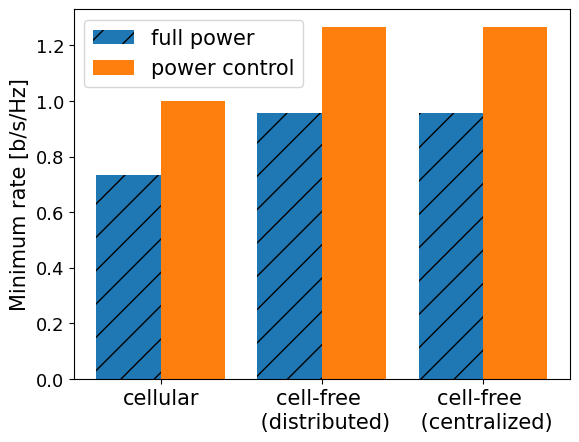

In [7]:
# Initialization
np.random.seed(0)
p_init = p_max*np.ones(K) # initial power vector: no power control, full power
R_centr = []
R_distr = []
R_cell = []
R_centr_full = []
R_distr_full = []
R_cell_full = []

parameters = []

beamformer = LTMMSE if bf == 'LTMMSE' else MF
#beamformer = LTMMSE
#beamformer = MF

for n in range(N_setups):
    # Generate AP and random UE positions
    pos = generate_setup(plot = False)
    # Compute path loss
    Gamma = compute_ch_statistics(pos)
    # Draw a list of N_sim channel realizations
    H_list = draw_channel_realizations(Gamma)
    # Compute user-centric clusters
    clusters = compute_clusters(Gamma,Q)
    # Draw a list of N_sim local channel estimates
    H_hat_list = compute_CSI_realizations(H_list,clusters[1])

    # Distributed cell-free
    W_list, Psi_list = compute_parameters_LTMMSE(H_hat_list,Gamma,clusters,p_init)
    #interf, signal, noise = compute_channel_coefficients(H_list,H_hat_list,LTMMSE,(W_list,Psi_list,p_init))
    interf, signal, noise = compute_channel_coefficients(H_list,H_hat_list,beamformer,(W_list,Psi_list,p_init))
    SINR = compute_SINR(interf,signal,noise,p_init)
    R_distr_full.append(log2(1+min(SINR)))
    p, _ = max_min_power_control(interf,signal,noise,p_max)
    SINR = compute_SINR(interf,signal,noise,p)  
    R_distr.append(log2(1+min(SINR))) 
    d_distributed = get_vectors(interf,signal,noise,p_max)

    parameters.append((interf, signal, noise))
    

    # Centralized cell-free
    _, Psi_list = compute_parameters_LTMMSE(H_hat_list,Gamma,clusters,p_init)
    #interf, signal, noise = compute_channel_coefficients(H_list,H_hat_list,MMSE,(clusters[0],Psi_list,p_init))
    if beamformer is not LTMMSE:
        interf, signal, noise = compute_channel_coefficients(H_list,H_hat_list,beamformer,(clusters[0],Psi_list,p_init))
    else:
        interf, signal, noise = compute_channel_coefficients(H_list,H_hat_list,MMSE,(clusters[0],Psi_list,p_init))

    SINR = compute_SINR(interf,signal,noise,p_init)
    R_centr_full.append(log2(1+min(SINR)))
    p, _ = max_min_power_control(interf,signal,noise,p_max)
    SINR = compute_SINR(interf,signal,noise,p)  
    R_centr.append(log2(1+min(SINR))) 
    d_centralized = get_vectors(interf,signal,noise,p_max)
    

    # Cellular (same as distributed cell-free, with Q = 1)
    clusters = compute_clusters(Gamma,1)
    H_hat_list = compute_CSI_realizations(H_list,clusters[1])
    W_list, Psi_list = compute_parameters_LTMMSE(H_hat_list,Gamma,clusters,p_init)
    #interf, signal, noise = compute_channel_coefficients(H_list,H_hat_list,LTMMSE,(W_list,Psi_list,p_init))
    interf, signal, noise = compute_channel_coefficients(H_list,H_hat_list,beamformer,(W_list,Psi_list,p_init))
    
    SINR = compute_SINR(interf,signal,noise,p_init)
    R_cell_full.append(log2(1+min(SINR)))
    p, _ = max_min_power_control(interf,signal,noise,p_max)
    SINR = compute_SINR(interf,signal,noise,p)  
    R_cell.append(log2(1+min(SINR))) 
    d_cell = get_vectors(interf,signal,noise,p_max)

    print("Progress: %.1f%%" % (100 * (n+1)/N_setups))

# Results
R_centr_avg = np.mean(R_centr)
R_distr_avg = np.mean(R_distr)
R_cell_avg = np.mean(R_cell)
R_centr_full_avg = np.mean(R_centr_full)
R_distr_full_avg = np.mean(R_distr_full)
R_cell_full_avg = np.mean(R_cell_full)

# Set width of bar
barWidth = 0.4
fontSize = 15
fig, ax = plt.subplots()
#ax.yaxis.grid(True)

# Set height of bar
full_power = [R_cell_full_avg, R_distr_full_avg, R_centr_full_avg]
power_control = [R_cell_avg, R_distr_avg, R_centr_avg]

# Set position of bar on X axis
br1 = np.arange(len(full_power))
br2 = [x + barWidth for x in br1]

# Make the plot
plt.bar(br1, full_power, width = barWidth, label ='full power',hatch="/")
plt.bar(br2, power_control, width = barWidth, label ='power control')

# Adding labels
plt.ylabel('Minimum rate [b/s/Hz]', fontsize = fontSize)
plt.xticks([r + barWidth/2 for r in range(len(full_power))], ['cellular', 'cell-free \n (distributed)', 'cell-free \n (centralized)'], fontsize = fontSize)
plt.yticks(fontsize = fontSize-2)
plt.legend(fontsize=fontSize)

In [8]:
print(parameters)

[(array([[484.25651458, 362.92663977, 338.94620495],
       [366.51824983, 220.94135086, 121.27254601],
       [338.94620495, 102.53603444, 447.34384138]]), array([2108.7194605 ,  646.69687924, 1493.80460302]), array([45.92079551, 25.43023553, 38.64976847]))]


In [3]:
ds = {'distributed': d_distributed, 'centralized': d_centralized, 'cellular': d_cell}
d = ds['distributed']

M = d['M'][0:3, 0:3]
u = d['u'][0:3]
direct_channels = d['b'][0:3]
Mk = d['Mks'][0][0:3, 0:3]

#alpha = 0/10*np.linalg.norm(M) * np.ones((3,1))
alpha = 0/10*np.diag(M)


print('alpha =', alpha)
display(np.diag(alpha.flatten()))

for desc, d in ds.items():
    for k in range(K):
        print('----------------------- ', k, '-----------------------------------')
        M = d['M'][0:3, 0:3]
        noise = d['u'][0:3]
        direct_channels = d['b'][0:3]
        Mk = d['Mks'][k][0:3, 0:3]

        print(' ****************', desc)
        print('norm:', np.linalg.norm(Mk))
        print('Mk')
        display(Mk)
        print('Inverse')
        display(np.linalg.inv(Mk+np.diag(alpha.flatten())))
        #np.linalg.eig(Mk)[0]
        print('Eigenvalues Mk')
        pprint(np.linalg.eig(Mk)[0]) 
        pprint(np.linalg.norm(Mk))

d = ds['distributed']

alpha = [0. 0. 0.]


array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]])

-----------------------  0 -----------------------------------
 **************** distributed
norm: 0.7627129578733632
Mk


array([[0.27960815, 0.039997  , 0.2737625 ],
       [0.00627244, 0.37109923, 0.01626452],
       [0.04819786, 0.04348129, 0.53364079]])

Inverse


...

Eigenvalues Mk
array([0.56437733, 0.43654282, 0.39188075])
0.8153236079729289
-----------------------  2 -----------------------------------
 **************** cellular
norm: 0.8153494087593202
Mk


array([[0.4437591 , 0.03791484, 0.02350681],
       [0.00610118, 0.39602951, 0.00643068],
       [0.04958629, 0.02541818, 0.55304573]])

Inverse


array([[ 2.26686819, -0.21099748, -0.09389819],
       [-0.03164636,  2.52989582, -0.0280719 ],
       [-0.2017938 , -0.09735681,  1.8178779 ]])

Eigenvalues Mk
array([0.56456775, 0.43640847, 0.39185812])
0.8153494087593202


In [4]:
def sinr(p, alpha=None):
    interference = M@p + u
    #sinr = np.squeeze([ direct_channels[k]*p[k]/(interference[k]+noise[k]) for k in range(M.shape[0])])
    if alpha is None:
        sinr = np.squeeze([ p[k]/(interference[k]) for k in range(M.shape[0])])
    else:
        sinr = np.squeeze([ p[k]/(interference[k]+alpha[k]*p[k]) for k in range(M.shape[0])])
    return sinr

In [5]:
npoints = 1000
x = list()
y = list()
z = list()

x2 = list()
y2 = list()
z2 = list()


norm = lambda x: np.linalg.norm(x, np.inf)

p = np.array([[1], [1], [1]])*p_max
utest = sinr(p, alpha=alpha).flatten()
utest2 = sinr(p).flatten()

scaling = utest2/utest

for _ in range(npoints):
    p = np.random.rand(3,1)
    p = p/norm(p) * p_max
    u1, u2, u3 = sinr(p).flatten()
    x.append(u1)
    y.append(u2)
    z.append(u3)

    u1, u2, u3 = sinr(p, alpha=alpha).flatten()
    x2.append(u1*scaling[0])
    y2.append(u2*scaling[1])
    z2.append(u3*scaling[2])

    
    

In [6]:
#ax = plt.figure().add_subplot(projection='3d')
#ax.plot_trisurf(x, y, z, linewidth=0.2, antialiased=True)
#plt.show()
scaling

array([1., 1., 1.])

<IPython.core.display.Javascript object>


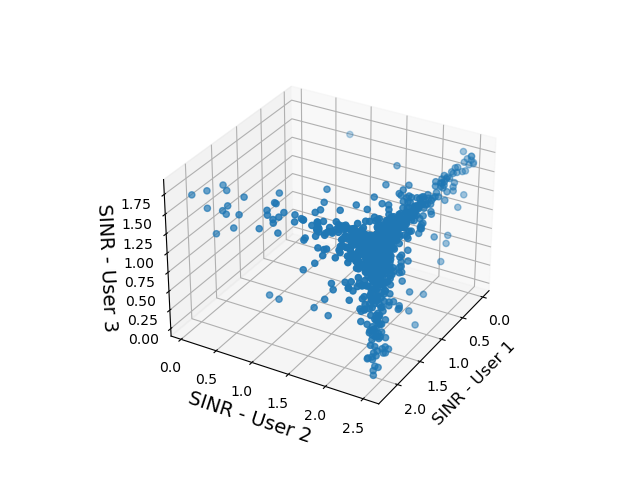

In [7]:
ax = plt.figure().add_subplot(projection='3d')
ax.scatter3D(x,y,z)
#ax.scatter3D(x2, y2, z2, color='r')

ax.set_xlabel("SINR - User 1", fontsize=12)
ax.set_ylabel("SINR - User 2", fontsize=14)
ax.set_zlabel("SINR - User 3", fontsize=14)
ax.view_init(elev=30, azim=30)  # Set elevation to 30° and azimuth to 45°

plt.savefig("sinr1.pdf", format="pdf")

plt.show()

<IPython.core.display.Javascript object>


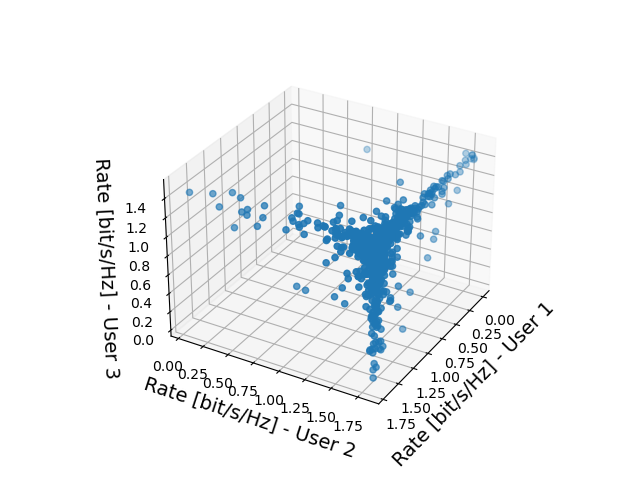

In [8]:
rate_x = np.log2(1+np.array(x) )
rate_y = np.log2(1+np.array(y) )
rate_z = np.log2(1+np.array(z) )
ax = plt.figure().add_subplot(projection='3d')
ax.scatter3D(rate_x, rate_y, rate_z)

ax.set_xlabel("Rate [bit/s/Hz] - User 1", fontsize=14)
ax.set_ylabel("Rate [bit/s/Hz] - User 2", fontsize=14)
ax.set_zlabel("Rate [bit/s/Hz] - User 3", fontsize=14)
ax.view_init(elev=30, azim=30)  # Set elevation to 30° and azimuth to 45°

plt.savefig("rate1.pdf", format="pdf")


plt.show()